# Scene classification (image-level labels)

We train a small CNN to assign **one scene class per image** — the most
important area represented. Seven classes are derived from the scene
vocabulary:

| class | scenes |
|---|---|
| cropland | fields, **forest_fields** |
| urban | urban, **urban_fringe** |
| coastal | coastal, **coastal_city** |
| mountain | mountain |
| arid | arid, **savanna**, **scrubland** |
| forest | forest, wilderness |
| pasture | pasture, **woodland_pasture** |

The **bold** scenes are deliberately ambiguous: `savanna` is dry ground with
nearly forest-dense trees, `scrubland` is rocky enough to pass for mountain,
`woodland_pasture` is a meadow that is half woodland, and `coastal_city` is a
grey harbour city. Each still gets the label of its dominant ground.

The **ambiguous** boundary scenes are intentionally kept: `forest_fields` is
labelled *cropland* (farmland dominates) and `urban_fringe` is labelled *urban*
(settlement dominates). Each image still gets exactly one label.

The model is a small CNN with global average pooling, trained with
cross-entropy on Apple **MPS**. Metrics: accuracy, per-class accuracy and a
confusion matrix.


## Learning objectives

By the end of this notebook you will be able to:

- turn rendered scenes into an **image-level classification** dataset (one label per image);
- build a small CNN with **global average pooling** as a classifier;
- train it with **cross-entropy** and read a **confusion matrix**;
- explain why the transitional scenes (`savanna`, `scrubland`, `woodland_pasture`,
  `coastal_city`, `forest_fields`, `urban_fringe`) are ambiguous.


### Key terms

- **logits** — the raw, unnormalised predictions the network outputs per class: ${z_c}$ is the predicted logit value for class $c$
- **softmax** — turns logits into a probability distribution,
  $p_c=e^{z_c}/\sum_k e^{z_k}$ (positive, sums to 1).
- **cross-entropy** — the loss that rewards high probability on the true class,
  $-\log p_y$.
- **confusion matrix** — counts of (true class, predicted class); the diagonal is
  correct and the off-diagonal is where errors concentrate.
- **global average pooling** — averaging feature maps over space into one vector.

In [1]:
# Google Colab does not preinstall torchinfo (a quiet no-op when it is already present).
%pip install -q torchinfo

Note: you may need to restart the kernel to use updated packages.


In [2]:
# On Google Colab, install mplsyn from GitHub (locally, the editable install is kept).
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install -q git+https://github.com/ogrisel/mplsyn.git")

In [3]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)


def pick_device():
    """Best available device: CUDA, then Apple MPS, then Intel XPU, else CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    return "cpu"


DEVICE = pick_device()
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU backend available: training will run on CPU (slower).")

torch 2.15.0 | device mps


## Dataset (balanced over classes)

The dataset is class-balanced, but **half of the images are mixtures**: two
scene types are blended with a soft, wavy boundary so each covers a near-equal
share of the frame. The rival class is drawn from a hand-picked **confusable**
set (forest versus pasture/cropland/arid, arid versus mountain/forest, coastal
versus urban, ...), and light blur/noise is added as in the other notebooks.

A near-balanced mixture has **no single correct label**, so it is assigned to
the target class with probability 0.65 and to the rival otherwise, independent
of which texture covers more area. That remaining ambiguity is irreducible:
even a perfect model cannot exceed the label agreement, which is exactly what
the confusion matrix and the least-confident gallery show.

This gives a ceiling that can be computed. Let $m=0.5$ be the fraction of mixtures and $c=0.65$ the label confidence. On a mixture the best any model can do is to predict the target scene's class, which agrees with the label with probability $c$; on a single scene it can agree with probability 1. So the accuracy of any model is bounded by

$$\text{accuracy}\le(1-m)\cdot 1+m\cdot c=0.5+0.5\times 0.65=0.825,$$

before even counting sensor noise and the 64 px resolution, which push the reachable value lower. The reported accuracy should be read against this 0.825 ceiling, not against 1. The other half are
single scenes, including the transitional types (`savanna`, `scrubland`,
`woodland_pasture`, `coastal_city`).

In [4]:
from mplsyn.datasets import (
    CLASSIFICATION_CLASSES,
    CLASSIFICATION_CLASS_INDEX,
    load_classification_data,
    split_classification,
)

SIZE = 64
N_PER_CLASS = 72
N_VAL_PER_CLASS = 16
N_TEST_PER_CLASS = 12
CLASSES = CLASSIFICATION_CLASSES
CLASS_INDEX = CLASSIFICATION_CLASS_INDEX
print("classes:", CLASSES)

class_images, class_labels = load_classification_data(N_PER_CLASS, SIZE)
# Three disjoint, class-balanced splits: fit / model selection / final report.
(train_images, val_images, test_images, train_labels, val_labels, test_labels) = (
    torch.from_numpy(array)
    for array in split_classification(class_images, class_labels, N_VAL_PER_CLASS, N_TEST_PER_CLASS)
)
print(
    "train",
    tuple(train_images.shape),
    "val",
    tuple(val_images.shape),
    "test",
    tuple(test_images.shape),
)

classes: ['arid', 'coastal', 'cropland', 'forest', 'mountain', 'pasture', 'urban']
train (309, 3, 64, 64) val (112, 3, 64, 64) test (84, 3, 64, 64)


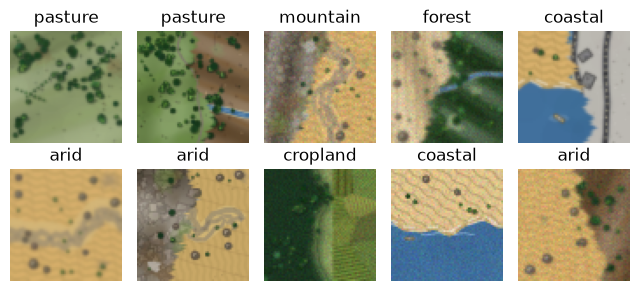

In [5]:
# A quick look at the data: random training images with their class label.
# A local random generator is used so that the global random state, hence the
# training results below, does not depend on this cell.
rng = np.random.default_rng(0)
sample_indices = rng.choice(len(train_images), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(6.5, 3.0))
for ax, sample_idx in zip(axes.ravel(), sample_indices, strict=True):
    ax.imshow(train_images[sample_idx].permute(1, 2, 0))
    ax.set_title(CLASSES[train_labels[sample_idx]])
    ax.axis("off")
plt.tight_layout()
plt.show()

**Figure read-out.** Random training images (64x64) with their single scene label.
- *What we see:* two `pasture` (light green meadow with scattered dark trees; green meadow with a brown patch and a blue stream), one `mountain` (grey rock track across tan ground), one `forest` (dark canopy on the right, tan strip on the left), two `coastal` (blue water against sand, one with grey harbour structures), three `arid` (tan ground with dark rocks, a grey rocky patch or a pale winding track) and one `cropland` (dark green with lighter field rows). Images are top-down, slightly blurred and noisy.
- *Defects:* (low) several frames mix two scene types with a soft boundary, yet carry one label, e.g. the `forest` image half covered by dry ground and the `mountain` image that looks like rocky arid terrain; this is the intended label ambiguity discussed above and bounds the reachable accuracy. (low) 10 images are too few to show every class: `urban` is absent from this sample.
- *Diversity:* 6 of the 7 classes appear, with varied colours, textures and layouts; the images within one class (the three `arid` scenes) differ clearly in rock and track content.


## Prediction and target spaces, loss and metric

Notation: $B$ is the batch size, $C=7$ the number of classes, $\mathbf 1[\cdot]$ the indicator function (1 if the condition holds, 0 otherwise) and $\log$ the natural logarithm.

- **Prediction** — the logits $z_b\in\mathbb R^{C}$ of image $b$ (`logits` ∈ ℝ^{B×7}). The class probabilities come from the softmax
  $$p_b^c=\mathrm{softmax}(z_b)_c=\frac{e^{z_b^c}}{\sum_{k=1}^{C}e^{z_b^k}},\qquad \sum_{c=1}^{C}p_b^c=1 .$$
- **Target** — $y_b\in\{0,\dots,C-1\}$, one class index per image (`y` ∈ {0,…,6}^B).

**Loss** — categorical cross-entropy, the mean negative log-probability given to the true class:

$$\mathcal{L} = -\frac{1}{B}\sum_{b=1}^{B}\log p_b^{\,y_b} = -\frac{1}{B}\sum_{b=1}^{B}\log \mathrm{softmax}(z_b)_{y_b}.$$

A model that outputs the uniform distribution ($p_b^c=1/C$) has $\mathcal L=\log 7\approx 1.95$: that is the chance-level loss to compare the loss curves with.

**Metrics** — with the predicted class $\hat y_b=\arg\max_c z_b^c$ (the softmax is monotonic, so the argmax of the logits is the argmax of the probabilities):
- accuracy $=\frac{1}{B}\sum_{b}\mathbf{1}[\hat y_b=y_b]$;
- confusion matrix $M_{ij}=\#\{b : y_b=i,\ \hat y_b=j\}$ (rows true, columns predicted), so that the accuracy is $\sum_i M_{ii}/\sum_{ij}M_{ij}$ and the per-class accuracy (recall) of class $i$ is $M_{ii}/\sum_j M_{ij}$.


In [6]:
# Loss and metric values on toy logits / labels (no model yet).
example_logits = torch.tensor(
    [
        [3.0, 1.0, 0.0, -1.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0],
    ]
)
example_labels = torch.tensor([0, 3, 6])
print("cross-entropy:", round(float(F.cross_entropy(example_logits, example_labels)), 3))
manual_loss = -F.log_softmax(example_logits, dim=1).gather(1, example_labels[:, None])[:, 0].mean()
print("manual CE:    ", round(float(manual_loss), 3))
predictions = example_logits.argmax(1)
print(
    "predictions:",
    predictions.tolist(),
    "| accuracy:",
    round(float((predictions == example_labels).float().mean()), 3),
)

cross-entropy: 0.687
manual CE:     0.687
predictions: [0, 3, 6] | accuracy: 1.0


## Model

In [7]:
class SceneCNN(nn.Module):
    """Small CNN with global average pooling for image-level scene labels."""

    def __init__(self, n_classes, base=24):
        super().__init__()

        def block(in_channels, out_channels, stride=2):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.features = nn.Sequential(
            block(3, base), block(base, base * 2), block(base * 2, base * 4)
        )
        self.head = nn.Linear(base * 4, n_classes)

    def forward(self, image_batch):
        pooled_features = self.features(image_batch).mean(dim=(2, 3))
        return self.head(pooled_features)


model = SceneCNN(len(CLASSES)).to(DEVICE)

## Exercise

Call the model on a a batch of 1 image with random pixels encoded on 3 color channels and size 64 (height) by 64 (width).

Measure the shape of the output.

Are output values between 0 and 1 and sum to one? Why?

In [8]:
# Write your answer here and execute the cell to check your answer.



In [9]:
# fmt: off
# Solution below (not not scrolll without having tried first!)

























batch_of_one_random_pixel_image = torch.randn(1, 3, 64, 64).to(DEVICE)
print(f"input shape: {batch_of_one_random_pixel_image.shape}")

predictions = model(batch_of_one_random_pixel_image)
print(f"output shape: {predictions.shape}")

predictions

input shape: torch.Size([1, 3, 64, 64])


output shape: torch.Size([1, 7])


tensor([[ 0.4175, -0.7935,  0.0181,  0.1841, -0.1013,  0.0924, -0.0758]],
       device='mps:0', grad_fn=<LinearBackward0>)

## Questions

Assume we call `model` with an `image_batch` argument that has shape `[1, 3, 64, 64]`. What is the shape of the feature maps at the output of each block?

What explain the change in the number of channels in the feature maps?

What explains the change in spatial dimension?

Which block as the largest number of trainable parameters?

**Answer first in your head, then execute the code below**

In [10]:
from torchinfo import summary

# One image through the network (batch size 1): shapes and counts are per sample.
summary(
    model,
    input_size=(1, 3, SIZE, SIZE),
    depth=2,
    mode="eval",
    device=DEVICE,
    verbose=0,
    col_names=("input_size", "output_size", "num_params", "mult_adds"),
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
SceneCNN                                 [1, 3, 64, 64]            [1, 7]                    --                        --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 96, 8, 8]             --                        --
│    └─Sequential: 2-1                   [1, 3, 64, 64]            [1, 24, 32, 32]           5,928                     5,972,064
│    └─Sequential: 2-2                   [1, 24, 32, 32]           [1, 48, 16, 16]           31,296                    7,962,816
│    └─Sequential: 2-3                   [1, 48, 16, 16]           [1, 96, 8, 8]             124,800                   7,963,008
├─Linear: 1-2                            [1, 96]                   [1, 7]                    679                       679
Total params: 162,703
Trainable params: 162,703
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 21.90
Inpu

### What `torchinfo` tells us about `SceneCNN`

Numbers below are per `64 x 64` RGB image (batch size 1). The `Mult-Adds` column counts multiply-accumulate operations; `torchinfo` labels its total with `Units.MEGABYTES`, which really means *millions* of multiply-adds.

- **Output shape.** Each stride-2 block halves the resolution and doubles the channels: `3x64x64 -> 24x32x32 -> 48x16x16 -> 96x8x8`. Global average pooling (a `mean` inside `forward`, so it has no row in the table) turns the `8x8` map into a 96-vector and the linear head into 7 logits: output `[1, 7]`. There is one vector per image and no spatial output, which is why this model can only give a scene-level label.
- **Parameters (162,703, about 163 k).** They pile up in the deepest block: 124,800, or 77 %, against 5,928 (4 %) in the first one. A `3x3` convolution costs `in x out x 9` weights, and the channel count has doubled twice. The linear head has only 679 weights (0.4 %), so the classifier itself is cheap and the features do the work.
- **Compute (about 22 M multiply-adds).** It is spread evenly over the blocks (6.0 M / 8.0 M / 8.0 M). Each stride-2 step divides the number of positions by 4 while the weights per position grow about 4x, so compute stays flat while parameters accumulate at the bottom.
- **Memory.** The weights take 0.65 MB, whereas one image's activations during forward and backward take about 1.4 MB. With a batch of 32, activations (about 44 MB) dominate over parameters.


## Training loop

### Training recipe

| item | value |
|---|---|
| model | small CNN + global average pooling (163 k params) |
| input | 64x64 RGB |
| loss | cross-entropy |
| optimiser | AdamW, lr 1e-3 |
| epochs / batch | 30 / 32 |
| data | 308 train / 112 val / 84 test, class-balanced; 50 % are two-scene mixtures |

Consider the following training setup and evaluation function:

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
EPOCHS, BATCH_SIZE = 30, 32
train_images_device = train_images.to(DEVICE)
train_labels_device = train_labels.to(DEVICE)


def evaluate(images, labels):
    """Validation loss, accuracy, confusion matrix and predictions for one split."""
    model.eval()
    with torch.no_grad():
        logits = model(images.to(DEVICE))
        loss = F.cross_entropy(logits, labels.to(DEVICE)).item()
        predictions = logits.argmax(1).cpu()
    accuracy = (predictions == labels).float().mean().item()
    confusion = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    for true_label, predicted_label in zip(labels.tolist(), predictions.tolist()):
        confusion[true_label, predicted_label] += 1
    return loss, accuracy, confusion, predictions

## Exercise

Implement the training loop in the cell below by filling in your code into the provided template and run it.

Recall the steps of a training loop:

For each epoch (one pass over the training set):

- iterate over batch of size `BATCH_SIZE` extracted from the training data in random order (you can do so manually using `torch.randperm` as done in the template or using the builtin features of the `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes):
    - take a random batch of input data and labels of size `BATCH_SIZE`,
    - reset the previously accumulated gradient values using the `optimizer`,
    - compute the predictions using the forward pass by applying the model to the batch of input data,
    - compute the loss value from the predictions and the 

- at the end of each epoch, evaluate the model on the validation data using the provided function and collect the results in a list

In [12]:
history = []

started = time.time()
for epoch in range(EPOCHS):
    model.train()  # question: why is this needed?
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        train_images_batch = train_images_device[batch_indices]
        train_labels_batch = train_labels_device[batch_indices]

        # TODO: write your code here and accumulate the loss value for the
        # batch in the variable running_loss.

    validation_loss, accuracy, _, _ = evaluate(val_images, val_labels)
    history.append((epoch, running_loss / len(train_images_device), validation_loss, accuracy))
    print(
        f"epoch {epoch:2d} | loss {running_loss / len(train_images_device):.3f}"
        f" | val loss {validation_loss:.3f} | val acc {accuracy:.3f}"
        f" | {time.time() - started:.0f}s"
    )

print("training time:", round(time.time() - started, 1), "s")

epoch  0 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  1 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  2 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  3 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  4 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  5 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  6 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  7 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  8 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch  9 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 10 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s


epoch 11 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 12 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 13 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 14 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 15 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 16 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 17 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 18 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 19 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 20 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 21 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 22 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 23 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s


epoch 24 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 25 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 26 | loss 0.000 | val loss 1.948 | val acc 0.143 | 0s
epoch 27 | loss 0.000 | val loss 1.948 | val acc 0.143 | 1s
epoch 28 | loss 0.000 | val loss 1.948 | val acc 0.143 | 1s
epoch 29 | loss 0.000 | val loss 1.948 | val acc 0.143 | 1s
training time: 0.5 s


In [13]:
# fmt: off
# Solution below (not not scrolll without having tried first!)

























history = []

started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        train_images_batch = train_images_device[batch_indices]
        train_labels_batch = train_labels_device[batch_indices]
        optimizer.zero_grad()
        loss = F.cross_entropy(model(train_images_batch), train_labels_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)

    validation_loss, accuracy, _, _ = evaluate(val_images, val_labels)
    history.append((epoch, running_loss / len(train_images_device), validation_loss, accuracy))
    print(
        f"epoch {epoch:2d} | loss {running_loss / len(train_images_device):.3f}"
        f" | val loss {validation_loss:.3f} | val acc {accuracy:.3f}"
        f" | {time.time() - started:.0f}s"
    )
print("training time:", round(time.time() - started, 1), "s")

epoch  0 | loss 1.453 | val loss 1.938 | val acc 0.188 | 0s
epoch  1 | loss 0.998 | val loss 1.893 | val acc 0.312 | 0s
epoch  2 | loss 0.845 | val loss 1.556 | val acc 0.393 | 0s
epoch  3 | loss 0.716 | val loss 1.355 | val acc 0.527 | 1s


epoch  4 | loss 0.644 | val loss 1.039 | val acc 0.625 | 1s
epoch  5 | loss 0.631 | val loss 0.813 | val acc 0.759 | 1s
epoch  6 | loss 0.606 | val loss 0.780 | val acc 0.705 | 1s
epoch  7 | loss 0.546 | val loss 0.724 | val acc 0.732 | 1s


epoch  8 | loss 0.525 | val loss 0.625 | val acc 0.741 | 1s
epoch  9 | loss 0.490 | val loss 0.583 | val acc 0.786 | 1s
epoch 10 | loss 0.440 | val loss 0.655 | val acc 0.714 | 1s
epoch 11 | loss 0.433 | val loss 0.705 | val acc 0.777 | 1s


epoch 12 | loss 0.491 | val loss 1.048 | val acc 0.625 | 1s
epoch 13 | loss 0.401 | val loss 1.235 | val acc 0.562 | 1s
epoch 14 | loss 0.390 | val loss 0.669 | val acc 0.732 | 1s


epoch 15 | loss 0.335 | val loss 0.645 | val acc 0.732 | 1s
epoch 16 | loss 0.315 | val loss 0.695 | val acc 0.741 | 1s
epoch 17 | loss 0.301 | val loss 0.834 | val acc 0.723 | 1s
epoch 18 | loss 0.250 | val loss 0.765 | val acc 0.750 | 2s


epoch 19 | loss 0.210 | val loss 0.725 | val acc 0.732 | 2s
epoch 20 | loss 0.175 | val loss 0.889 | val acc 0.696 | 2s
epoch 21 | loss 0.165 | val loss 0.728 | val acc 0.759 | 2s
epoch 22 | loss 0.112 | val loss 0.629 | val acc 0.777 | 2s


epoch 23 | loss 0.093 | val loss 0.593 | val acc 0.795 | 2s
epoch 24 | loss 0.088 | val loss 0.606 | val acc 0.786 | 2s
epoch 25 | loss 0.077 | val loss 0.738 | val acc 0.750 | 2s
epoch 26 | loss 0.065 | val loss 0.700 | val acc 0.759 | 2s


epoch 27 | loss 0.057 | val loss 0.615 | val acc 0.804 | 2s
epoch 28 | loss 0.045 | val loss 0.618 | val acc 0.768 | 2s
epoch 29 | loss 0.033 | val loss 0.685 | val acc 0.759 | 2s
training time: 2.2 s


## Evaluation

We report validation and test accuracy, per-class accuracy, the confusion
matrix, the **training and validation loss curves** (plus validation
accuracy) and the **majority-class baseline** (always predicting the most
common training class). The baseline is the score to beat: with seven
balanced classes it sits near 1/7, so the model's accuracy is only
meaningful above it. Watching the two loss curves together shows whether
the model is still learning or starting to overfit.

validation accuracy 0.759
test accuracy       0.786   <- reported once, never used for tuning
per-class accuracy:
  arid      0.81  (13/16)
  coastal   0.69  (11/16)
  cropland  0.62  (10/16)
  forest    0.81  (13/16)
  mountain  0.94  (15/16)
  pasture   0.50  (8/16)
  urban     0.94  (15/16)
majority-class baseline accuracy 0.143 (always predict 'forest')


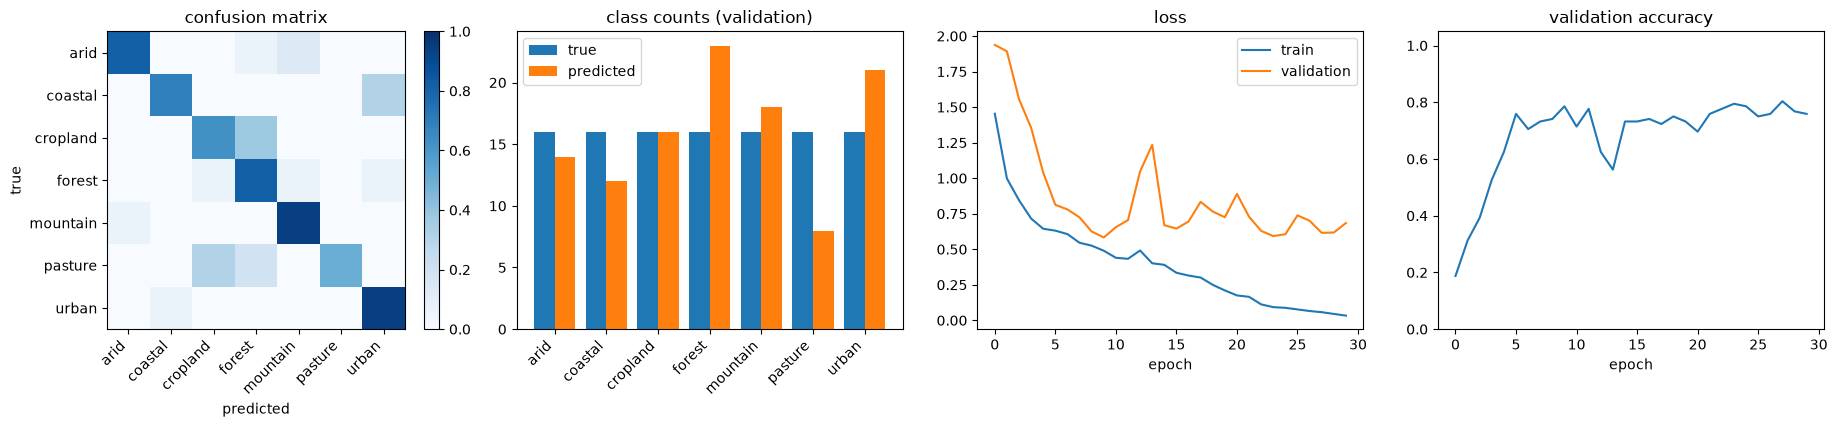

In [14]:
validation_loss, accuracy, confusion, predictions = evaluate(val_images, val_labels)
test_loss, test_accuracy, test_confusion, test_predictions = evaluate(test_images, test_labels)
print(f"validation accuracy {accuracy:.3f}")
print(f"test accuracy       {test_accuracy:.3f}   <- reported once, never used for tuning")
print("per-class accuracy:")
for class_id, class_name in enumerate(CLASSES):
    total = confusion[class_id].sum()
    print(
        f"  {class_name:9s} {confusion[class_id, class_id] / total:.2f}  ({confusion[class_id, class_id]}/{total})"
    )

# Trivial baseline: always predict the most frequent training class. A score is
# only meaningful relative to what "doing nothing" already achieves.
majority_class = int(np.bincount(train_labels.numpy()).argmax())
baseline_accuracy = (val_labels == majority_class).float().mean().item()
print(
    f"majority-class baseline accuracy {baseline_accuracy:.3f} "
    f"(always predict '{CLASSES[majority_class]}')"
)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
confusion_normalized = confusion / confusion.sum(axis=1, keepdims=True)
image = axes[0].imshow(confusion_normalized, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
axes[0].set_yticks(range(len(CLASSES)), CLASSES)
axes[0].set_xlabel("predicted")
axes[0].set_ylabel("true")
axes[0].set_title("confusion matrix")
fig.colorbar(image, ax=axes[0], fraction=0.046)
# Class histogram beside the CM: a class the model over-predicts shows a
# predicted bar taller than its true bar, which explains column asymmetries.
true_counts = np.bincount(val_labels.numpy(), minlength=len(CLASSES))
predicted_counts = np.bincount(predictions.numpy(), minlength=len(CLASSES))
positions = np.arange(len(CLASSES))
axes[1].bar(positions - 0.2, true_counts, width=0.4, label="true")
axes[1].bar(positions + 0.2, predicted_counts, width=0.4, label="predicted")
axes[1].set_xticks(positions, CLASSES, rotation=45, ha="right")
axes[1].set_title("class counts (validation)")
axes[1].legend()
epochs = [row[0] for row in history]
axes[2].plot(epochs, [row[1] for row in history], label="train")
axes[2].plot(epochs, [row[2] for row in history], label="validation")
axes[2].set_title("loss")
axes[2].set_xlabel("epoch")
axes[2].legend()
axes[3].plot(epochs, [row[3] for row in history])
axes[3].set_title("validation accuracy")
axes[3].set_xlabel("epoch")
axes[3].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Figure read-out.** Left: confusion matrix (rows true, columns predicted) - with the ambiguous mixtures the errors now sit **off the diagonal**. Second: class counts (true vs predicted) - read it beside the matrix. Third: train vs validation loss. Right: validation accuracy. A validation loss that flattens high while accuracy plateaus means the remaining error is **label ambiguity**, not underfitting.

## How noisy is a single number?

A reported accuracy is one draw from a random process: the weight
initialisation and the batch order both depend on the seed. Re-train
the same model with three different seeds on a short schedule and look at the
spread. Differences smaller than this spread are **noise**, not signal — a
lesson that applies to every model in these notebooks.

With $K$ seeds giving accuracies $a_1,\dots,a_K$ we report the mean $\bar a=\frac1K\sum_k a_k$ and the **sample** standard deviation $s=\sqrt{\frac{1}{K-1}\sum_k (a_k-\bar a)^2}$ (with the $K-1$ divisor: with only $K=3$ runs, dividing by $K$ would underestimate the spread by a factor $\sqrt{2/3}\approx 0.82$).

validation accuracy over 3 seeds: ['0.759', '0.714', '0.652']
mean 0.708 | std 0.054


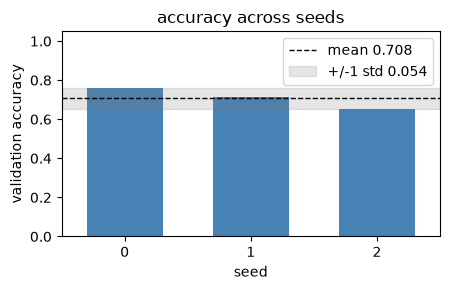

In [15]:
def train_with_seed(seed, epochs=15):
    """Train a fresh classifier with one seed; return validation accuracy."""
    torch.manual_seed(seed)
    candidate = SceneCNN(len(CLASSES)).to(DEVICE)
    candidate_optimizer = torch.optim.AdamW(candidate.parameters(), lr=1e-3)
    for _ in range(epochs):
        candidate.train()
        permutation = torch.randperm(len(train_images_device), device=DEVICE)
        for start in range(0, len(train_images_device), BATCH_SIZE):
            batch_indices = permutation[start : start + BATCH_SIZE]
            candidate_optimizer.zero_grad()
            loss = F.cross_entropy(
                candidate(train_images_device[batch_indices]), train_labels_device[batch_indices]
            )
            loss.backward()
            candidate_optimizer.step()
    candidate.eval()
    with torch.no_grad():
        predictions = candidate(val_images.to(DEVICE)).argmax(1).cpu()
    return (predictions == val_labels).float().mean().item()


seed_accuracies = [train_with_seed(seed) for seed in (0, 1, 2)]
print("validation accuracy over 3 seeds:", [f"{value:.3f}" for value in seed_accuracies])
print(f"mean {np.mean(seed_accuracies):.3f} | std {np.std(seed_accuracies, ddof=1):.3f}")

# The spread is the point: plot it so a single number is read against its noise.
seed_mean, seed_std = float(np.mean(seed_accuracies)), float(np.std(seed_accuracies, ddof=1))
fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.bar(["0", "1", "2"], seed_accuracies, color="steelblue", width=0.6)
ax.axhline(seed_mean, color="black", linestyle="--", linewidth=1, label=f"mean {seed_mean:.3f}")
ax.fill_between(
    [-0.5, 2.5],
    seed_mean - seed_std,
    seed_mean + seed_std,
    color="grey",
    alpha=0.2,
    label=f"+/-1 std {seed_std:.3f}",
)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 1.05)
ax.set_xlabel("seed")
ax.set_ylabel("validation accuracy")
ax.set_title("accuracy across seeds")
ax.legend()
plt.tight_layout()
plt.show()

**Figure read-out.** Validation accuracy for three independent runs. The error bar is the run-to-run standard deviation: any difference smaller than it is **noise, not signal**, so a single-run number should always be quoted with this spread in mind.

## Example predictions

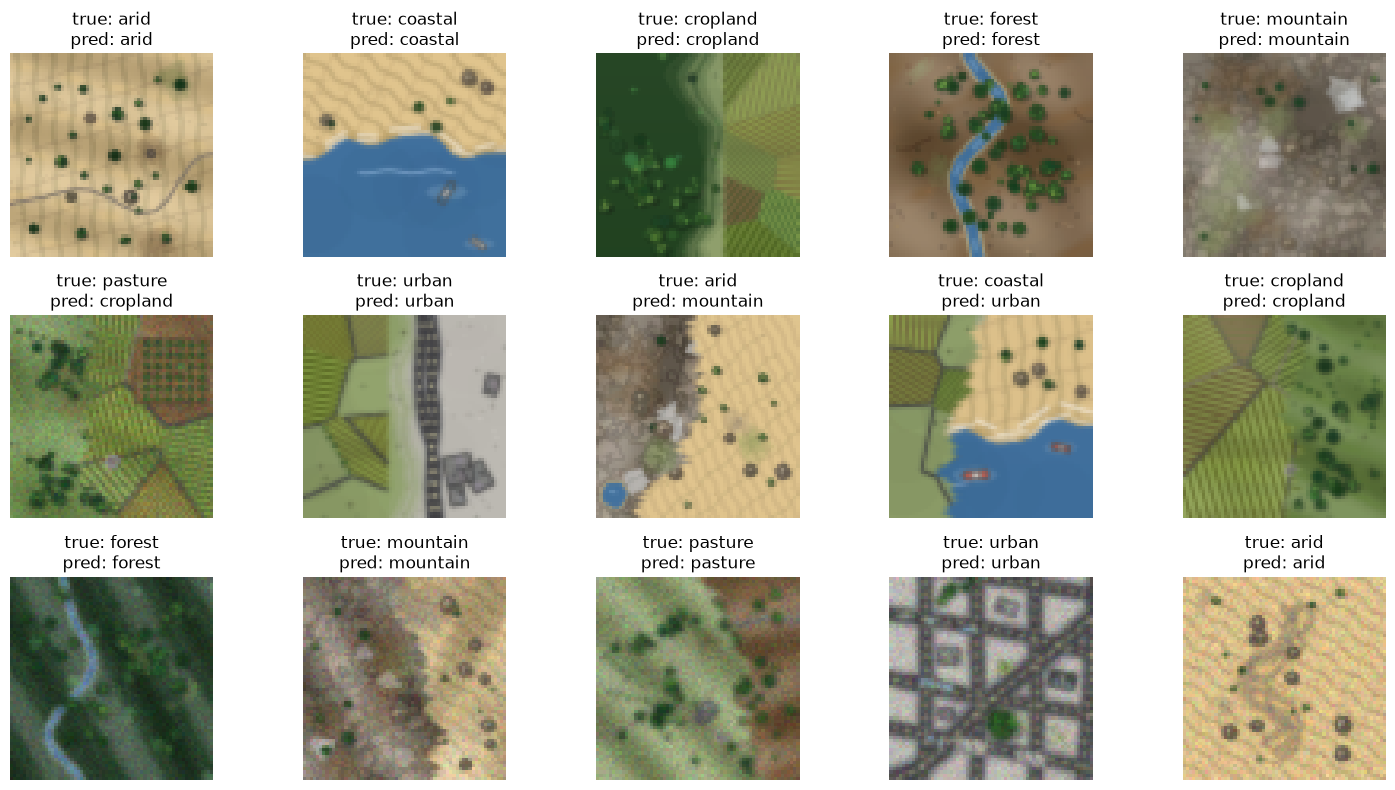

In [16]:
# Qualitative check: three rows of five validation scenes, sampled round-robin
# across the classes so the grid is not dominated by one label.
per_class = {
    class_id: (val_labels == class_id).nonzero().flatten().tolist()
    for class_id in range(len(CLASSES))
}
sample_indices, class_cursor = [], 0
while len(sample_indices) < 15:
    class_id = class_cursor % len(CLASSES)
    if per_class[class_id]:
        sample_indices.append(per_class[class_id].pop(0))
    class_cursor += 1

fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for sample_idx, ax in zip(sample_indices, axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    ax.set_title(
        f"true: {CLASSES[val_labels[sample_idx]]}\npred: {CLASSES[predictions[sample_idx]]}",
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

**Figure read-out.** Fifteen validation scenes with true/predicted labels: correct on the textbook scenes, with the mistakes on the near-balanced mixtures and boundary scenes, where a single label is a convention.

### Evaluation protocol and failure gallery

We keep three disjoint splits: **train** (fit the weights), **validation**
(monitor the training curves and compare runs) and **test** (reported once, never
used for any decision). Here the weights after the last epoch are the ones evaluated: no
checkpoint is selected. Reporting a held-out test score is what makes the number
trustworthy. Below are the validation scenes on which the classifier is the least confident (it still
predicts some of them correctly).

/var/folders/93/0_k_9bh97fj_15hzk2bhy5r00000gn/T/ipykernel_91316/1149969468.py:18: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


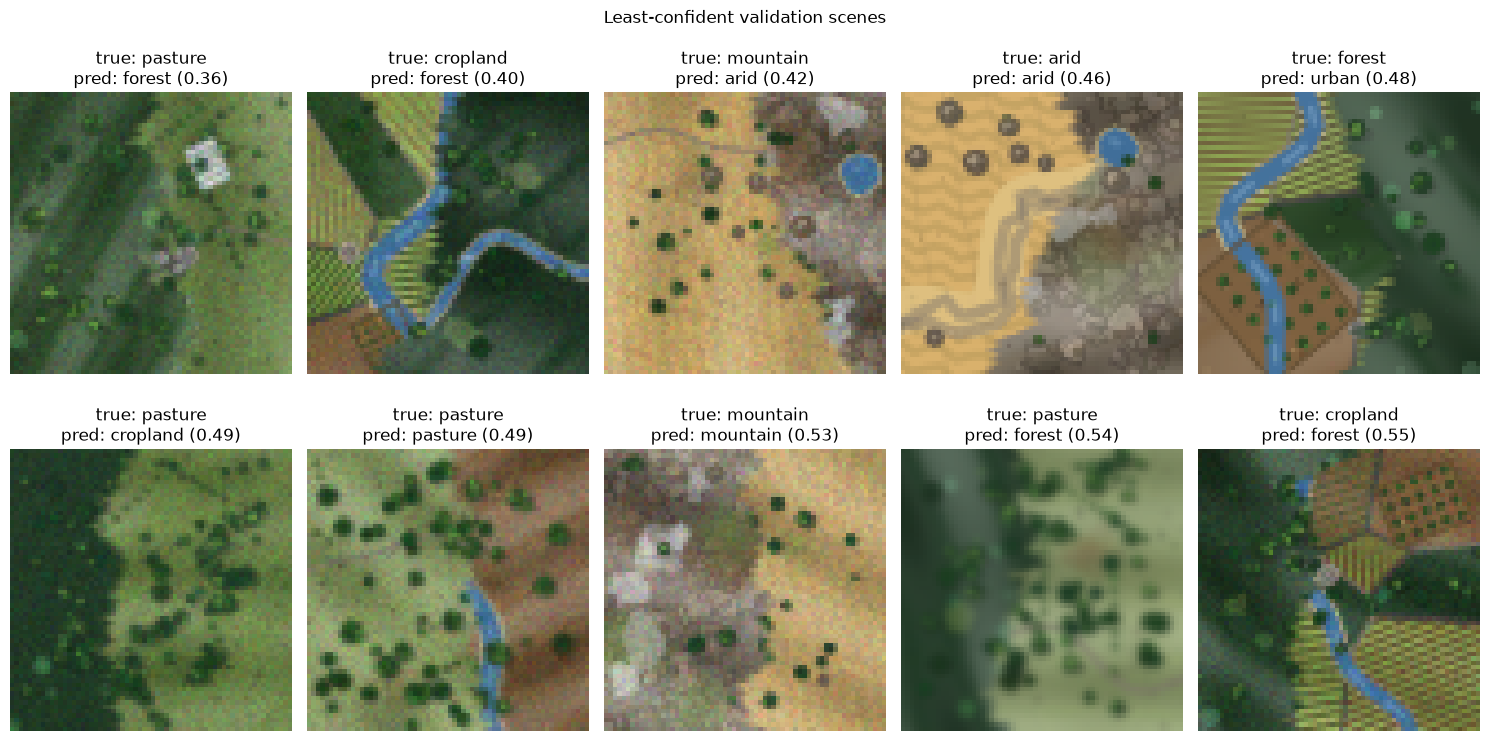

In [17]:
# "Where does the model hesitate?" gallery: the ten least-confident validation
# predictions (lowest max softmax), with the true and predicted label.
model.eval()
with torch.no_grad():
    probabilities = torch.softmax(model(val_images.to(DEVICE)), dim=1).cpu()
confidence = probabilities.max(1).values
order = confidence.argsort().flatten().tolist()

fig, axes = plt.subplots(2, 5, figsize=(15, 8), constrained_layout=True)
for ax, sample_idx in zip(axes.ravel(), order[:10]):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    ax.set_title(
        f"true: {CLASSES[val_labels[sample_idx]]}\n"
        f"pred: {CLASSES[predictions[sample_idx]]} ({confidence[sample_idx]:.2f})",
    )
    ax.axis("off")
plt.suptitle("Least-confident validation scenes")
plt.tight_layout()
plt.show()

**Figure read-out.** The ten least-confident validation scenes (lowest max softmax). Three of the ten are still predicted correctly, so low confidence is not the same as an error. Most of them show two scene types sharing the frame (forest next to pasture or fields, rock next to sand), and one is a strongly blurred meadow: the model's uncertainty flags the label ambiguity and the degraded images.

This notebook classifies **64x64** scene thumbnails. At that size, boundary
scenes (`forest_fields`, `urban_fringe`) genuinely share texture and layout, so
some confusion is intrinsic to the task, not a modelling failure.

### Interpreting these numbers

The scores above are measured on **deliberately hard** imagery, not a clean
benchmark, and that is the point of a synthetic dataset:

- **High accuracy on clean images can mislead.** A classifier that only sees
  pristine renders can look near-perfect and still fail on the first hazy or
  blurry acquisition; a slightly lower number on degraded data is the more
  honest summary of real-world performance.
- **Resolution bounds what can be recovered.** At `64 x 64` a whole city block is
  only a few pixels, so fine distinctions between scene types are lost.
- **Some "errors" are label ambiguity.** Each class now mixes a textbook scene
  with a transitional one: `savanna` is labelled arid though it is nearly
  forest-dense, `scrubland` is labelled arid though it is rocky like mountain,
  `woodland_pasture` is labelled pasture though half woodland, `coastal_city` is
  labelled coastal though it is a grey city, and the boundary scenes
  (`forest_fields`, `urban_fringe`) take their dominant ground's label. A mixed
  scene has no single correct label.
- **Accuracy hides which classes fail.** Read it together with the confusion
  matrix and the least-confident gallery, never as a single number.

The takeaway is not "the model is bad", but "these metrics quantify **robustness
under realistic conditions**"; improving them means investing in resolution or
priors, not just a bigger network.

The dataset is also **deliberately ambiguous**: half the images are
near-balanced mixtures whose label is only 65 % aligned with the target
scene. No model can decode which half of a 50/50 frame was "meant" as the
label, so the accuracy of any model is capped at 0.825 (the ceiling computed above, before
sensor noise and the 64 px resolution lower it further). Our scores sit a bit below this
ceiling and the gap to 1.0 is irreducible, not a modelling failure. Read the confusion matrix as the real
lesson: `coastal` is often taken for `urban`, `mountain` for `arid`, and
`forest`/`pasture`/`cropland` blur together.
